#**Задание. Найти шаблон на изображении. (изображение и шаблон выдаются преподавателем)**

Особых точек на сцене:   8000
Особых точек на шаблоне: 203
Хороших совпадений: 2
Найдено кластеров: 1
Лучший кластер: 0, точек в нём: 2
Центр объекта: (451, 551)


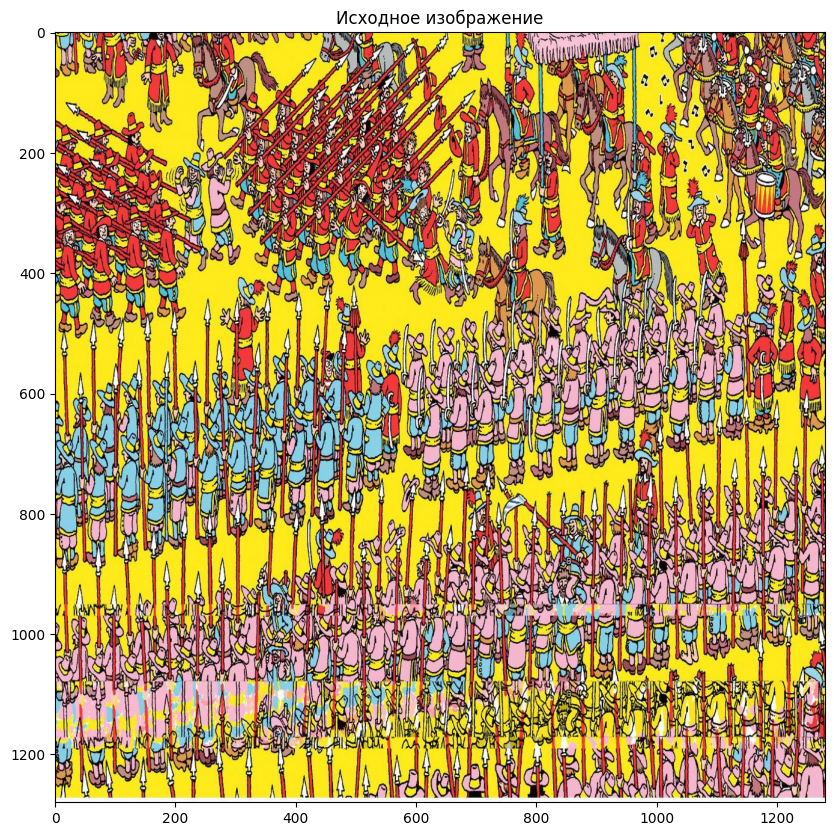

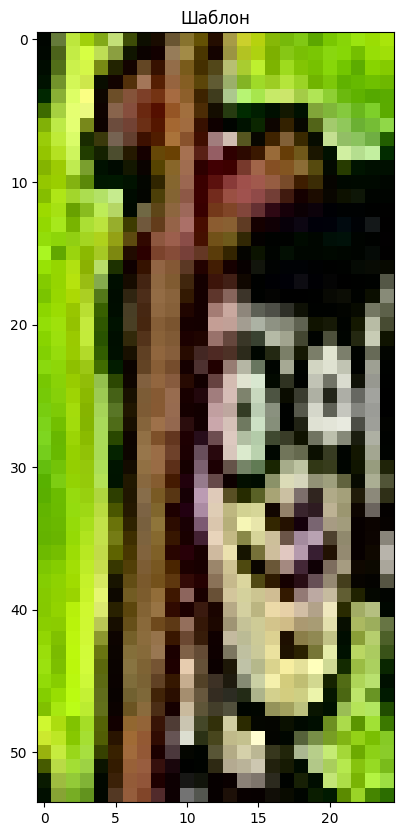

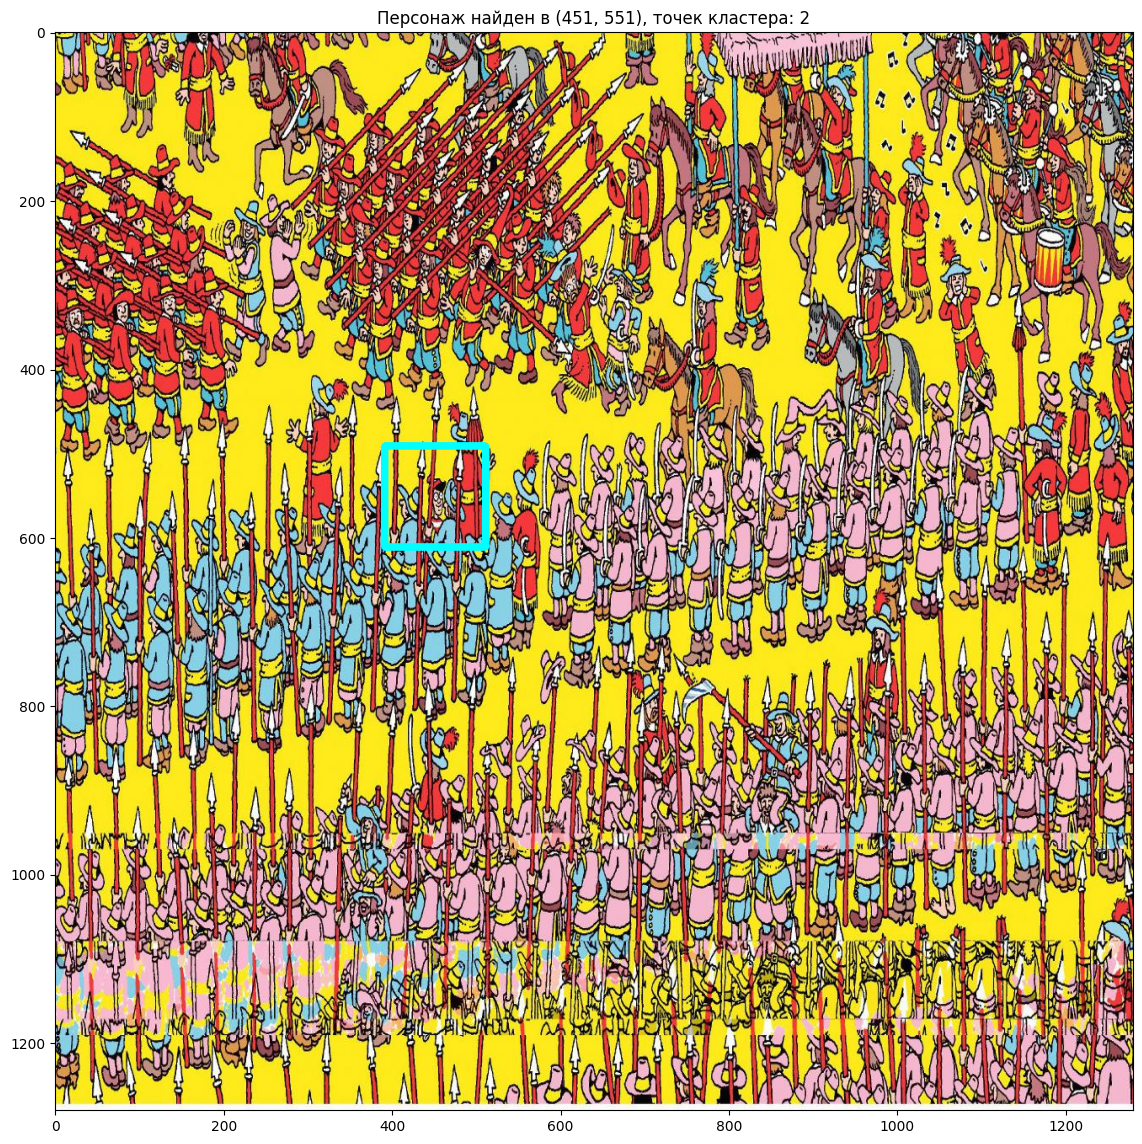

In [4]:
# -*- coding: utf-8 -*-
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MeanShift, estimate_bandwidth

WIDTH_SIZE, HEIGHT_SIZE = 15, 10
plt.rcParams["figure.figsize"] = [WIDTH_SIZE, HEIGHT_SIZE]

# ---------- 1. Загрузка ----------
rgb_img  = cv2.imread('44.jpg')     # большое изображение
template = cv2.imread('23.JPG')     # шаблон

if rgb_img is None or template is None:
    raise FileNotFoundError("Проверьте имена файлов: 44.jpg и 23.jpg")

rgb_img  = cv2.cvtColor(rgb_img,  cv2.COLOR_BGR2RGB)
template = cv2.cvtColor(template, cv2.COLOR_BGR2RGB)

plt.figure(); plt.imshow(rgb_img);  plt.title('Исходное изображение')
plt.figure(); plt.imshow(template); plt.title('Шаблон')

# ---------- 2. Оттенки серого + увеличение шаблона ----------
gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_BGR2GRAY)

scale = 5.0    # шаблон маленький — увеличиваем, чтобы SIFT нашёл детали
template_big = cv2.resize(
    template,
    (int(template.shape[1] * scale), int(template.shape[0] * scale)),
    interpolation=cv2.INTER_CUBIC
)
gray_templ = cv2.cvtColor(template_big, cv2.COLOR_BGR2GRAY)

# ---------- 3. SIFT ----------
sift = cv2.SIFT_create(nfeatures=8000)
k_1, des_1 = sift.detectAndCompute(gray_img,     None)   # сцена
k_2, des_2 = sift.detectAndCompute(gray_templ,   None)   # шаблон

print(f"Особых точек на сцене:   {len(k_1)}")
print(f"Особых точек на шаблоне: {len(k_2)}")

# ---------- 4. Сопоставление ----------
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des_2, des_1, k=2)   # для каждой точки шаблона — 2 ближайших на сцене

good = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:     # ratio test Лоу
        good.append(m)

print(f"Хороших совпадений: {len(good)}")

# ---------- 5. Кластеризация ----------
points = np.float32([k_1[m.trainIdx].pt for m in good])   # точки на сцене

bandwidth = estimate_bandwidth(points, quantile=0.2, n_samples=len(points))
if bandwidth <= 0:
    bandwidth = 50.0

ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms.fit(points)

# ---------- 6. Ищем САМЫЙ ПЛОТНЫЙ кластер ----------
best_label = None
best_count = 0
for label in np.unique(ms.labels_):
    cnt = np.sum(ms.labels_ == label)
    if cnt > best_count:
        best_count = cnt
        best_label = label

print(f"Найдено кластеров: {len(np.unique(ms.labels_))}")
print(f"Лучший кластер: {best_label}, точек в нём: {best_count}")

# Координаты центра самого плотного кластера
cluster_points = points[ms.labels_ == best_label]
cx, cy = np.mean(cluster_points, axis=0).astype(int)
print(f"Центр объекта: ({cx}, {cy})")

# ---------- 7. Рисуем КВАДРАТ вокруг персонажа ----------
plot_img = rgb_img.copy()

# Размер квадрата — на основе разброса точек кластера
std = np.std(cluster_points, axis=0)
half = int(max(std[0], std[1]) * 3)   # коэффициент можно подстроить (2–4)
half = max(half, 60)                  # не меньше 60 px, чтобы точно было видно

top_left     = (cx - half, cy - half)
bottom_right = (cx + half, cy + half)

cv2.rectangle(plot_img, top_left, bottom_right, (0, 255, 255), 8)

plt.figure(figsize=(14, 14))
plt.imshow(plot_img)
plt.title(f'Персонаж найден в ({cx}, {cy}), точек кластера: {best_count}')
plt.show()